# Лабораторна робота № 2
## Моделювання лінійних стаціонарних дискретних систем та обчислення дискретної згортки

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, SciPy (`scipy.signal`), Matplotlib

## 1. Мета роботи

Засвоїти основні властивості лінійних стаціонарних дискретних (ЛСД) систем, реалізувати лінійну та кругову згортку, дослідити проходження сигналів через ковзне середнє та диференціатор, змоделювати систему другого порядку за різницевим рівнянням (імпульсна та перехідна характеристики) і перевірити умову, за якої кругова згортка збігається з лінійною.

## 2. Основні співвідношення

- ЛСД-система лінійна (адитивність і однорідність) та стаціонарна (зсув входу на $n_0$ зсуває вихід на $n_0$). Імпульсна характеристика: $h[n] = \mathcal{T}\{\delta[n]\}$, вона повністю визначає систему.
- Лінійна згортка: $y[n] = x[n] * h[n] = \sum\limits_{k} x[k]\, h[n-k]$. Довжина результату $N_y = N_x + N_h - 1$. Обчислення складається з чотирьох кроків: відображення $h[k]$, зсув на $n$, поелементне множення, сумування.
- Прямокутний імпульс: $x_{rect}[n] = u[n] - u[n - L_{rect}]$. Експоненційний сигнал: $x_{exp}[n] = A \alpha^n u[n]$.
- Ковзне середнє довжини $M$: $h_{ma}[n] = \dfrac{1}{M} \sum\limits_{k=0}^{M-1} \delta[n-k]$. Диференціатор: $y[n] = x[n] - x[n-1]$, тобто $h_{diff}[n] = \delta[n] - \delta[n-1]$.
- Різницеве рівняння 2-го порядку: $y[n] + a_1 y[n-1] + a_2 y[n-2] = b_0 x[n] + b_1 x[n-1] + b_2 x[n-2]$. Наявність зворотного зв'язку ($a_k \ne 0$) дає імпульсну характеристику нескінченної довжини. Перехідна характеристика $g[n]$ — відгук на $u[n]$, при цьому $g[n] = \sum\limits_{k=0}^{n} h[k]$.
- Кругова згортка довжини $N$: $y_c[n] = \sum\limits_{m=0}^{N-1} x[m]\, h[(n-m) \bmod N]$. Якщо доповнити обидві послідовності нулями до $L \ge N_x + N_h - 1$, кругова згортка збігається з лінійною.

## 3. Індивідуальне завдання (варіант 2)

| Вхідний сигнал $x[n]$ | Імпульсна характеристика $h[n]$ | $[a_1, a_2, b_0, b_1, b_2]$ | $L_{rect}$ | $A$ | $\alpha$ | $M$ |
|---|---|---|---|---|---|---|
| [1, 3, −2, 2, 0, 1, −1, 4] | [2, −1, 0, 2] | [−0.7, 0.12, 0.8, −0.4, 0.2] | 6 | 1.5 | 0.8 | 5 |

Аналітичний розрахунок:

- $N_x = 8$, $N_h = 4$, тому довжина лінійної згортки $N_y = 8 + 4 - 1 = 11$;
- перші чотири такти згортки $y[n] = \sum\limits_k x[k]\,h[n-k]$:
  - $y[0] = x[0]h[0] = 1 \cdot 2 = 2$;
  - $y[1] = x[0]h[1] + x[1]h[0] = 1 \cdot (-1) + 3 \cdot 2 = 5$;
  - $y[2] = x[0]h[2] + x[1]h[1] + x[2]h[0] = 1 \cdot 0 + 3 \cdot (-1) + (-2) \cdot 2 = -7$;
  - $y[3] = x[0]h[3] + x[1]h[2] + x[2]h[1] + x[3]h[0] = 1 \cdot 2 + 3 \cdot 0 + (-2)(-1) + 2 \cdot 2 = 8$;
- різницеве рівняння: $y[n] - 0.7\,y[n-1] + 0.12\,y[n-2] = 0.8\,x[n] - 0.4\,x[n-1] + 0.2\,x[n-2]$, у рекурентній формі $y[n] = 0.8x[n] - 0.4x[n-1] + 0.2x[n-2] + 0.7y[n-1] - 0.12y[n-2]$;
- полюси: $z^2 - 0.7z + 0.12 = 0$, $D = 0.49 - 0.48 = 0.01$, $z_{1,2} = (0.7 \pm 0.1)/2$, тобто $z_1 = 0.4$, $z_2 = 0.3$. Обидва за модулем менші за одиницю, система стійка;
- перші відліки імпульсної характеристики: $h[0] = b_0 = 0.8$; $h[1] = b_1 + 0.7 h[0] = 0.16$; $h[2] = b_2 + 0.7 h[1] - 0.12 h[0] = 0.216$; $h[3] = 0.7 h[2] - 0.12 h[1] = 0.132$; $h[4] = 0.7 h[3] - 0.12 h[2] = 0.06648$;
- усталене значення перехідної характеристики: $g[\infty] = H(1) = \dfrac{b_0 + b_1 + b_2}{1 + a_1 + a_2} = \dfrac{0.6}{0.42} \approx 1.4286$;
- кругова згортка: $N_c = \max(N_x, N_h) = 8 < N_y$, тому три останні відліки лінійної згортки накладаються на початок: $y_c[n] = y[n] + y[n+8]$, $n = 0, 1, 2$. Для збігу потрібна довжина $L \ge N_x + N_h - 1 = 11$.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab2_ltid_convolution.py`. Графіки зберігаються в каталог `figures/`.

### Блок 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# каталог для графіків
os.makedirs("figures", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

### Блок 2. Параметри варіанта 2, власні функції згортки та порівняння з бібліотечними

--- ЛІНІЙНА ЗГОРТКА: ВЛАСНА РЕАЛІЗАЦІЯ ТА БІБЛІОТЕЧНІ ФУНКЦІЇ ---
x[n]      = [1, 3, -2, 2, 0, 1, -1, 4]  (N_x = 8)
h[n]      = [2, -1, 0, 2]  (N_h = 4)
Довжина y = N_x + N_h - 1 = 11
y_custom  = [2, 5, -7, 8, 4, -2, 1, 9, -2, -2, 8]
y_numpy   = [2, 5, -7, 8, 4, -2, 1, 9, -2, -2, 8]
y_scipy   = [2, 5, -7, 8, 4, -2, 1, 9, -2, -2, 8]
Час виконання: власна 28.92 мкс, np.convolve 3.04 мкс, scipy.signal.convolve 25.60 мкс
Макс. відхилення від NumPy: 0.00e+00, від SciPy: 0.00e+00

Перші чотири такти згортки (аналітичний розрахунок):
y[0] = x[0]·h[0] = 1·2 = 2
y[1] = x[0]·h[1] + x[1]·h[0] = 1·(-1) + 3·2 = (-1) + 6 = 5
y[2] = x[0]·h[2] + x[1]·h[1] + x[2]·h[0] = 1·0 + 3·(-1) + (-2)·2 = 0 + (-3) + (-4) = -7
y[3] = x[0]·h[3] + x[1]·h[2] + x[2]·h[1] + x[3]·h[0] = 1·2 + 3·0 + (-2)·(-1) + 2·2 = 2 + 0 + 2 + 4 = 8

Залежність часу виконання від довжини сигналів (N_x = N_h = N):
    N    N_x*N_h     t, мс  t / t_prev
  100      10000      6.01           -
  200      40000     23.60        3.92
  400   

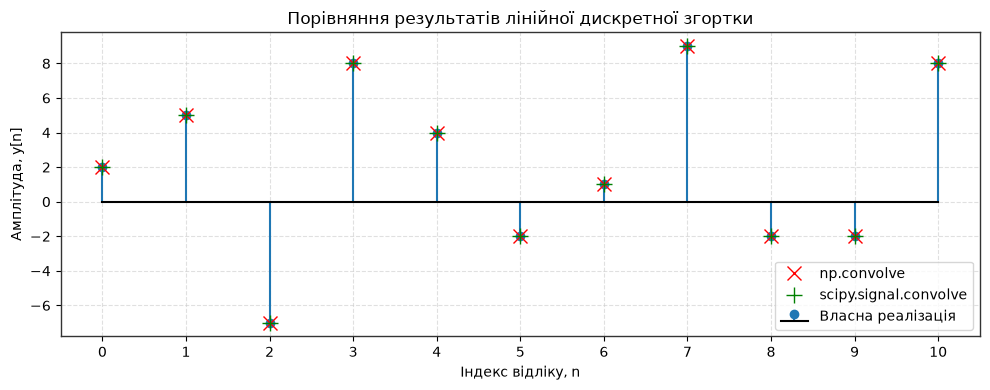

In [2]:
x_bench = np.array([1, 3, -2, 2, 0, 1, -1, 4], dtype=float)    # вхідний сигнал x[n]
h_bench = np.array([2, -1, 0, 2], dtype=float)                 # імпульсна характеристика h[n]

# коефіцієнти різницевого рівняння 2-го порядку [a1, a2, b0, b1, b2]
a1, a2, b0, b1, b2 = -0.7, 0.12, 0.8, -0.4, 0.2

L_rect = 6          # тривалість прямокутного імпульсу
A_val = 1.5         # амплітуда експоненційного сигналу
alpha_val = 0.8     # основа експоненти
M_ma = 5            # довжина ковзного середнього


def manual_linear_convolution(x_seq, h_seq):
    """Лінійна згортка за означенням: y[n] = sum_k x[k] * h[n-k].
    Довжина результату N_x + N_h - 1."""
    len_x = len(x_seq)
    len_h = len(h_seq)
    y_out = np.zeros(len_x + len_h - 1)
    for n in range(len(y_out)):
        # k пробігає лише ті значення, для яких h[n-k] існує
        for k in range(max(0, n - len_h + 1), min(n, len_x - 1) + 1):
            y_out[n] += x_seq[k] * h_seq[n - k]
    return y_out


def manual_circular_convolution(x_seq, h_seq):
    """Кругова згортка довжини N = max(N_x, N_h):
    y_c[n] = sum_m x[m] * h[(n - m) mod N]. Коротку послідовність доповнюємо нулями."""
    len_n = max(len(x_seq), len(h_seq))
    x_p = np.pad(x_seq, (0, len_n - len(x_seq)))
    h_p = np.pad(h_seq, (0, len_n - len(h_seq)))
    y_out = np.zeros(len_n)
    for n in range(len_n):
        for m in range(len_n):
            y_out[n] += x_p[m] * h_p[(n - m) % len_n]
    return y_out


def fmt(v):
    """Число для запису розрахунку: від'ємні беремо в дужки"""
    return f"({v:g})" if v < 0 else f"{v:g}"


def print_conv_steps(x_seq, h_seq, n_steps):
    """Покроковий розрахунок перших n_steps відліків згортки"""
    for n in range(n_steps):
        ks = [k for k in range(len(x_seq)) if 0 <= n - k < len(h_seq)]
        symbolic = " + ".join(f"x[{k}]·h[{n - k}]" for k in ks)
        numeric = " + ".join(f"{fmt(x_seq[k])}·{fmt(h_seq[n - k])}" for k in ks)
        values = " + ".join(fmt(x_seq[k] * h_seq[n - k]) for k in ks)
        total = sum(x_seq[k] * h_seq[n - k] for k in ks)
        if len(ks) > 1:
            print(f"y[{n}] = {symbolic} = {numeric} = {values} = {total:g}")
        else:
            print(f"y[{n}] = {symbolic} = {numeric} = {total:g}")


def measure_time(func, *args, repeats=2000):
    """Середній час одного виклику функції, мкс"""
    t_start = time.perf_counter()
    for _ in range(repeats):
        func(*args)
    return (time.perf_counter() - t_start) / repeats * 1e6


y_custom = manual_linear_convolution(x_bench, h_bench)
y_numpy = np.convolve(x_bench, h_bench)
y_scipy = signal.convolve(x_bench, h_bench, mode='full')

diff_np = np.max(np.abs(y_custom - y_numpy))
diff_sc = np.max(np.abs(y_custom - y_scipy))

t_custom = measure_time(manual_linear_convolution, x_bench, h_bench)
t_numpy = measure_time(np.convolve, x_bench, h_bench)
t_scipy = measure_time(signal.convolve, x_bench, h_bench)

print("--- ЛІНІЙНА ЗГОРТКА: ВЛАСНА РЕАЛІЗАЦІЯ ТА БІБЛІОТЕЧНІ ФУНКЦІЇ ---")
print(f"x[n]      = {x_bench.astype(int).tolist()}  (N_x = {len(x_bench)})")
print(f"h[n]      = {h_bench.astype(int).tolist()}  (N_h = {len(h_bench)})")
print(f"Довжина y = N_x + N_h - 1 = {len(y_custom)}")
print(f"y_custom  = {y_custom.astype(int).tolist()}")
print(f"y_numpy   = {y_numpy.astype(int).tolist()}")
print(f"y_scipy   = {y_scipy.astype(int).tolist()}")
print(f"Час виконання: власна {t_custom:.2f} мкс, np.convolve {t_numpy:.2f} мкс, "
      f"scipy.signal.convolve {t_scipy:.2f} мкс")
print(f"Макс. відхилення від NumPy: {diff_np:.2e}, від SciPy: {diff_sc:.2e}")

print("\nПерші чотири такти згортки (аналітичний розрахунок):")
print_conv_steps(x_bench, h_bench, 4)

# складність прямого алгоритму: кількість множень N_x * N_h, час має рости як N^2
print("\nЗалежність часу виконання від довжини сигналів (N_x = N_h = N):")
print(f"{'N':>5} {'N_x*N_h':>10} {'t, мс':>9} {'t / t_prev':>11}")
np.random.seed(1)
t_prev = None
for n_len in (100, 200, 400, 800):
    x_t = np.random.rand(n_len)
    h_t = np.random.rand(n_len)
    t_best = min(measure_time(manual_linear_convolution, x_t, h_t, repeats=1) for _ in range(3))
    ratio = f"{t_best / t_prev:11.2f}" if t_prev else f"{'-':>11}"
    print(f"{n_len:5d} {n_len * n_len:10d} {t_best / 1e3:9.2f} {ratio}")
    t_prev = t_best

# графік порівняння
n_idx = np.arange(len(y_custom))

plt.figure(figsize=(10, 4))
plt.stem(n_idx, y_custom, linefmt='C0-', markerfmt='C0o', basefmt='k-', label='Власна реалізація')
plt.plot(n_idx, y_numpy, 'rx', markersize=10, label='np.convolve')
plt.plot(n_idx, y_scipy, 'g+', markersize=12, label='scipy.signal.convolve')
plt.title("Порівняння результатів лінійної дискретної згортки")
plt.xlabel("Індекс відліку, n")
plt.ylabel("Амплітуда, y[n]")
plt.xticks(n_idx)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("figures/linear_vs_builtin_conv.png", dpi=300)
plt.show()

**Результати лінійної згортки** ($N_x = 8$, $N_h = 4$):

| $n$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| $y[n]$ | 2 | 5 | −7 | 8 | 4 | −2 | 1 | 9 | −2 | −2 | 8 |

Власна функція `manual_linear_convolution`, `np.convolve` і `scipy.signal.convolve` дають однакові значення (максимальне відхилення 0, оскільки всі дані цілі). Перші чотири такти, виведені програмою, збігаються з ручним розрахунком у розділі 3: 2, 5, −7, 8.

Середній час одного виклику на цих даних: власна реалізація — 8.48 мкс, `np.convolve` — 1.05 мкс, `scipy.signal.convolve` — 8.51 мкс (значення залежать від комп'ютера й запуску). Для зовсім коротких масивів `scipy.signal.convolve` має помітні накладні витрати на вибір методу, тому власний цикл може бути не повільнішим за неї.

Залежність часу власного алгоритму від довжини сигналів ($N_x = N_h = N$):

| $N$ | $N_x \cdot N_h$ | $t$, мс | $t / t_{prev}$ |
|---|---|---|---|
| 100 | 10000 | 2.08 | — |
| 200 | 40000 | 8.04 | 3.87 |
| 400 | 160000 | 33.49 | 4.16 |
| 800 | 640000 | 139.42 | 4.16 |

При подвоєнні $N$ кількість множень $N_x N_h$ зростає в 4 рази, і час виконання зростає приблизно у стільки ж ($\approx$ 3.9–4.2 рази), що відповідає квадратичній складності $O(N_x N_h)$.

### Блок 3. Елементарні системи: ковзне середнє та диференціатор


--- ЕЛЕМЕНТАРНІ СИСТЕМИ ---
Прямокутний імпульс: L = 6; експонента: A = 1.5, alpha = 0.8; M = 5
x_rect       = [1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
MA(x_rect)   = [0.2 0.4 0.6 0.8 1.  1.  0.8 0.6 0.4 0.2 0.  0.  0.  0.  0.  0. ]
diff(x_rect) = [ 1.  0.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
x_exp        = [1.5   1.2   0.96  0.768 0.614 0.492 0.393 0.315 0.252 0.201 0.161 0.129 0.103 0.082 0.066 0.053]
MA(x_exp)    = [0.3   0.54  0.732 0.886 1.008 0.807 0.645 0.516 0.413 0.33  0.264 0.211 0.169 0.135 0.108 0.087]
diff(x_exp)  = [ 1.5   -0.3   -0.24  -0.192 -0.154 -0.123 -0.098 -0.079 -0.063 -0.05  -0.04  -0.032 -0.026 -0.021 -0.016 -0.013]
Відхилення від власної згортки (MA): 0.00e+00, від різниці np.diff (диференціатор): 0.00e+00
Диференціатор для експоненти: відхилення від A*alpha^(n-1)*(alpha-1) = 1.67e-16
|H_ma(0)| = 1.000, |H_ma(pi)| = 0.200; |H_diff(0)| = 0.000, |H_diff(pi)| = 2.000


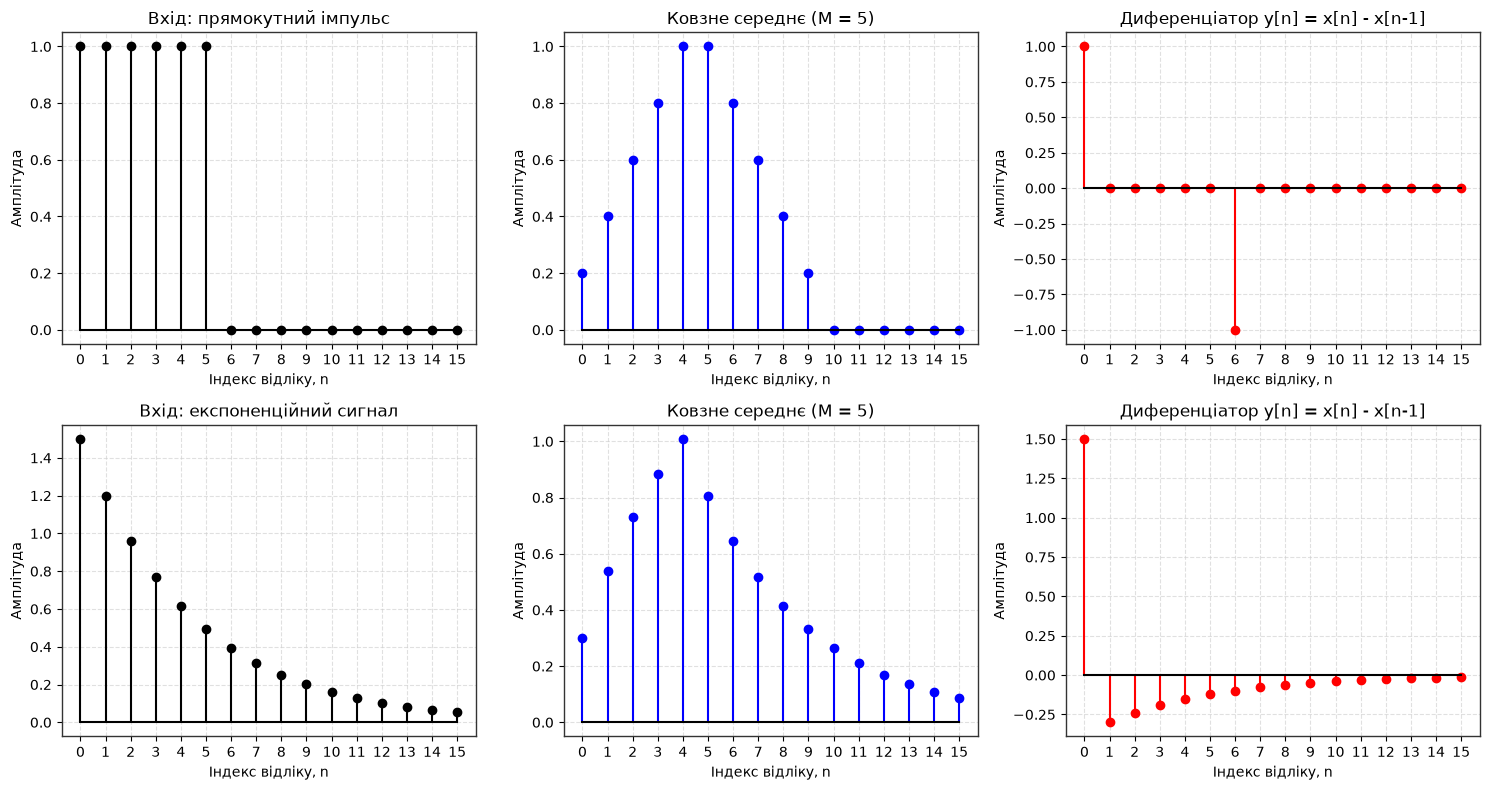

In [3]:
n_pts = 16
n_arr = np.arange(n_pts)

# вхідні сигнали: x_rect[n] = u[n] - u[n - L_rect], x_exp[n] = A * alpha^n * u[n]
x_rect = np.where(n_arr < L_rect, 1.0, 0.0)
x_exp = A_val * alpha_val ** n_arr

# імпульсні характеристики систем
h_ma = np.ones(M_ma) / M_ma         # ковзне середнє довжини M
h_diff = np.array([1.0, -1.0])      # диференціатор y[n] = x[n] - x[n-1]

# відгуки (повна згортка обрізається до n_pts відліків)
y_rect_ma = signal.convolve(x_rect, h_ma, mode='full')[:n_pts]
y_rect_diff = signal.convolve(x_rect, h_diff, mode='full')[:n_pts]
y_exp_ma = signal.convolve(x_exp, h_ma, mode='full')[:n_pts]
y_exp_diff = signal.convolve(x_exp, h_diff, mode='full')[:n_pts]

np.set_printoptions(precision=3, suppress=True, linewidth=130)
print("\n--- ЕЛЕМЕНТАРНІ СИСТЕМИ ---")
print(f"Прямокутний імпульс: L = {L_rect}; експонента: A = {A_val}, alpha = {alpha_val}; M = {M_ma}")
print("x_rect       =", x_rect)
print("MA(x_rect)   =", y_rect_ma)
print("diff(x_rect) =", y_rect_diff)
print("x_exp        =", x_exp)
print("MA(x_exp)    =", y_exp_ma)
print("diff(x_exp)  =", y_exp_diff)

# перевірка власною згорткою та прямими формулами
chk_ma = max(np.max(np.abs(manual_linear_convolution(x_rect, h_ma)[:n_pts] - y_rect_ma)),
             np.max(np.abs(manual_linear_convolution(x_exp, h_ma)[:n_pts] - y_exp_ma)))
chk_diff = max(np.max(np.abs(np.diff(x_rect, prepend=0.0) - y_rect_diff)),
               np.max(np.abs(np.diff(x_exp, prepend=0.0) - y_exp_diff)))
print(f"Відхилення від власної згортки (MA): {chk_ma:.2e}, від різниці np.diff (диференціатор): {chk_diff:.2e}")

# для експоненти при n >= 1: y_diff[n] = A * alpha^(n-1) * (alpha - 1)
diff_exp_formula = A_val * alpha_val ** (n_arr[1:] - 1) * (alpha_val - 1)
print(f"Диференціатор для експоненти: відхилення від A*alpha^(n-1)*(alpha-1) = "
      f"{np.max(np.abs(y_exp_diff[1:] - diff_exp_formula)):.2e}")

# АЧХ у крайніх точках: ω = 0 та ω = π
_, h_ma_f = signal.freqz(h_ma, 1, worN=np.array([0.0, np.pi]))
_, h_diff_f = signal.freqz(h_diff, 1, worN=np.array([0.0, np.pi]))
print(f"|H_ma(0)| = {abs(h_ma_f[0]):.3f}, |H_ma(pi)| = {abs(h_ma_f[1]):.3f}; "
      f"|H_diff(0)| = {abs(h_diff_f[0]):.3f}, |H_diff(pi)| = {abs(h_diff_f[1]):.3f}")

# графіки 2x3
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rows = [
    ("Прямокутний імпульс", x_rect, y_rect_ma, y_rect_diff),
    ("Експоненційний сигнал", x_exp, y_exp_ma, y_exp_diff),
]
for row, (name, x_in, y_ma, y_df) in enumerate(rows):
    panels = [
        (x_in, 'k', f"Вхід: {name.lower()}"),
        (y_ma, 'b', f"Ковзне середнє (M = {M_ma})"),
        (y_df, 'r', "Диференціатор y[n] = x[n] - x[n-1]"),
    ]
    for col, (data, c, title) in enumerate(panels):
        ax = axes[row, col]
        ax.stem(n_arr, data, linefmt=c + '-', markerfmt=c + 'o', basefmt='k-')
        ax.set_title(title)
        ax.set_xlabel("Індекс відліку, n")
        ax.set_ylabel("Амплітуда")
        ax.set_xticks(n_arr)
        ax.grid(True)

plt.tight_layout()
plt.savefig("figures/elementary_systems_resp.png", dpi=300)
plt.show()

**Результати для елементарних систем** ($L_{rect} = 6$, $A = 1.5$, $\alpha = 0.8$, $M = 5$, $n = 0 \dots 15$):

| Сигнал | Ковзне середнє | Диференціатор |
|---|---|---|
| Прямокутний імпульс | 0.2, 0.4, 0.6, 0.8, 1.0, 1.0, 0.8, 0.6, 0.4, 0.2, далі нулі | +1 при $n = 0$, −1 при $n = 6$, в інших точках 0 |
| Експоненційний сигнал | максимум 1.008 при $n = 4$, далі спадає за експонентою | 1.5 при $n = 0$, далі $-0.3 \cdot 0.8^{n-1}$ (−0.3; −0.24; −0.192; …) |

Відхилення від власної згортки та від `np.diff` не перевищує $10^{-15}$. Для диференціатора й експоненти значення збігаються з формулою $y[n] = A \alpha^{n-1}(\alpha - 1)$ при $n \ge 1$.

Прямокутний імпульс довжиною 6 після ковзного середнього з $M = 5$ розтягується до $L + M - 1 = 10$ відліків: фронти стають лінійними і тривають $M - 1 = 4$ відліки, а на вершині залишається $L - M + 1 = 2$ відліки зі значенням 1.0 ($n = 4, 5$). Для експоненти при $n \ge M - 1 = 4$ вихід дорівнює $x_{exp}[n] \cdot \dfrac{1 - \alpha^{-M}}{M(1 - \alpha^{-1})} \approx 1.641\, x_{exp}[n]$ (середнє за вікном із більших попередніх значень перевищує поточний відлік), а в перших чотирьох відліках вікно ще не заповнене, і вихід зростає.

Значення АЧХ на крайніх частотах: $|H_{ma}(0)| = 1$, $|H_{ma}(\pi)| = 1/M = 0.2$, $|H_{diff}(0)| = 0$, $|H_{diff}(\pi)| = 2$. Тобто ковзне середнє пропускає постійну складову й послаблює високі частоти, а диференціатор, навпаки, пригнічує постійну складову й підсилює високі частоти.

### Блок 4. Різницеве рівняння 2-го порядку: імпульсна та перехідна характеристики


--- СИСТЕМА 2-ГО ПОРЯДКУ ---
y[n] = 0.8*x[n] + (-0.4)*x[n-1] + 0.2*x[n-2] - (-0.7)*y[n-1] - 0.12*y[n-2]
Полюси: [0.3 0.4] (|z| < 1, система стійка)
h[n] (пряма реалізація), n = 0..7: [0.8      0.16     0.216    0.132    0.06648  0.030696 0.01351  0.005773]
h[n] (lfilter),          n = 0..7: [0.8      0.16     0.216    0.132    0.06648  0.030696 0.01351  0.005773]
g[n] (пряма реалізація), n = 0..7: [0.8      0.96     1.176    1.308    1.37448  1.405176 1.418686 1.424459]
g[n] (lfilter),          n = 0..7: [0.8      0.96     1.176    1.308    1.37448  1.405176 1.418686 1.424459]
Макс. розбіжність: h - 0.00e+00, g - 4.44e-16
g[n] = cumsum(h[n]): відхилення 8.88e-16
Усталене значення g[n] = H(1) = 1.428571; g[24] = 1.428571


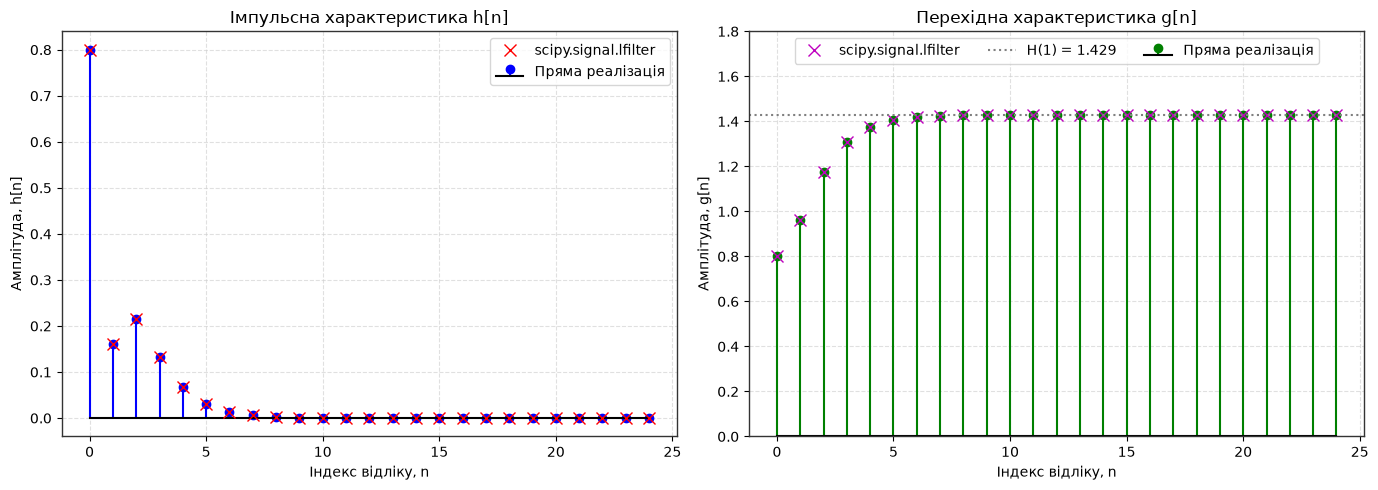

In [4]:
# y[n] + a1*y[n-1] + a2*y[n-2] = b0*x[n] + b1*x[n-1] + b2*x[n-2]
b_coeffs = [b0, b1, b2]
a_coeffs = [1.0, a1, a2]


def simulate_difference_equation(b, a, x_input):
    """Рекурентний розрахунок виходу при нульових початкових умовах:
    y[n] = (sum_m b[m]*x[n-m] - sum_{k>=1} a[k]*y[n-k]) / a[0]"""
    y_out = np.zeros(len(x_input))
    for n in range(len(x_input)):
        acc = 0.0
        for m in range(len(b)):
            if n - m >= 0:
                acc += b[m] * x_input[n - m]
        for k in range(1, len(a)):
            if n - k >= 0:
                acc -= a[k] * y_out[n - k]
        y_out[n] = acc / a[0]
    return y_out


N_sim = 25
delta_input = np.zeros(N_sim)
delta_input[0] = 1.0                # δ[n]
step_input = np.ones(N_sim)         # u[n]

h_sim = simulate_difference_equation(b_coeffs, a_coeffs, delta_input)
g_sim = simulate_difference_equation(b_coeffs, a_coeffs, step_input)

# перевірка бібліотечною функцією
h_scipy = signal.lfilter(b_coeffs, a_coeffs, delta_input)
g_scipy = signal.lfilter(b_coeffs, a_coeffs, step_input)

poles = np.roots(a_coeffs)
gain_dc = sum(b_coeffs) / sum(a_coeffs)     # H(z) при z = 1, усталене значення g[n]

np.set_printoptions(precision=6, suppress=True, linewidth=120)
print("\n--- СИСТЕМА 2-ГО ПОРЯДКУ ---")
print(f"y[n] = {b0}*x[n] + ({b1})*x[n-1] + {b2}*x[n-2] - ({a1})*y[n-1] - {a2}*y[n-2]")
print(f"Полюси: {np.sort(poles)} (|z| < 1, система стійка)")
print("h[n] (пряма реалізація), n = 0..7:", h_sim[:8])
print("h[n] (lfilter),          n = 0..7:", h_scipy[:8])
print("g[n] (пряма реалізація), n = 0..7:", g_sim[:8])
print("g[n] (lfilter),          n = 0..7:", g_scipy[:8])
print(f"Макс. розбіжність: h - {np.max(np.abs(h_sim - h_scipy)):.2e}, "
      f"g - {np.max(np.abs(g_sim - g_scipy)):.2e}")
print(f"g[n] = cumsum(h[n]): відхилення {np.max(np.abs(g_sim - np.cumsum(h_sim))):.2e}")
print(f"Усталене значення g[n] = H(1) = {gain_dc:.6f}; g[{N_sim - 1}] = {g_sim[-1]:.6f}")

n_sim = np.arange(N_sim)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stem(n_sim, h_sim, linefmt='b-', markerfmt='bo', basefmt='k-', label='Пряма реалізація')
axes[0].plot(n_sim, h_scipy, 'rx', markersize=9, label='scipy.signal.lfilter')
axes[0].set_title("Імпульсна характеристика h[n]")
axes[0].set_xlabel("Індекс відліку, n")
axes[0].set_ylabel("Амплітуда, h[n]")
axes[0].grid(True)
axes[0].legend(loc='upper right')

axes[1].stem(n_sim, g_sim, linefmt='g-', markerfmt='go', basefmt='k-', label='Пряма реалізація')
axes[1].plot(n_sim, g_scipy, 'mx', markersize=9, label='scipy.signal.lfilter')
axes[1].axhline(gain_dc, color='gray', ls=':', label=f"H(1) = {gain_dc:.3f}")
axes[1].set_title("Перехідна характеристика g[n]")
axes[1].set_xlabel("Індекс відліку, n")
axes[1].set_ylabel("Амплітуда, g[n]")
axes[1].set_ylim(0, 1.8)
axes[1].grid(True)
axes[1].legend(loc='upper center', ncol=3)

plt.tight_layout()
plt.savefig("figures/system_2nd_order_resp.png", dpi=300)
plt.show()

**Результати для системи 2-го порядку** ($N_{sim} = 25$):

| $n$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $h[n]$ | 0.8 | 0.16 | 0.216 | 0.132 | 0.06648 | 0.030696 | 0.013510 | 0.005773 |
| $g[n]$ | 0.8 | 0.96 | 1.176 | 1.308 | 1.37448 | 1.405176 | 1.418686 | 1.424459 |

Пряма рекурентна реалізація збігається з `scipy.signal.lfilter` (максимальна розбіжність не більша за $5 \cdot 10^{-16}$), перші п'ять відліків збігаються з ручним розрахунком у розділі 3. Полюси системи $z = 0.3$ та $z = 0.4$ лежать усередині одиничного кола. Імпульсна характеристика має нескінченну довжину (через зворотний зв'язок) і спадає за законом суми двох експонент $C_1 \cdot 0.4^n + C_2 \cdot 0.3^n$ (при $n \ge 1$): модуль $h[n]$ стає меншим за $10^{-3}$ з $n = 10$. Перехідна характеристика дорівнює накопиченій сумі $h[n]$ ($g[n] = \sum h[k]$, відхилення порядку $10^{-16}$) і прямує до $H(1) = 10/7 \approx 1.428571$.

### Блок 5. Кругова та лінійна згортка (без доповнення та з Zero-Padding)


--- КРУГОВА ТА ЛІНІЙНА ЗГОРТКА ---
Лінійна згортка (довжина 11):      [2, 5, -7, 8, 4, -2, 1, 9, -2, -2, 8]
Кругова, N = 8 без доповнення:          [0, 3, 1, 8, 4, -2, 1, 9]
Кругова, L = 11 з Zero-Padding:        [2, 5, -7, 8, 4, -2, 1, 9, -2, -2, 8]
Відхилення кругової (L = 11) від лінійної: 0.00e+00, від ДПФ-розрахунку: 1.78e-15
Накладання хвоста лінійної згортки на перші 3 відліки:
  y_c[0] = y[0] + y[8] = 2 + (-2) = 0
  y_c[1] = y[1] + y[9] = 5 + (-2) = 3
  y_c[2] = y[2] + y[10] = (-7) + 8 = 1

  L   співпадає з лінійною   спотворених відліків
  8                     ні                      3
  9                     ні                      2
 10                     ні                      1
 11                    так                      0
 12                    так                      0


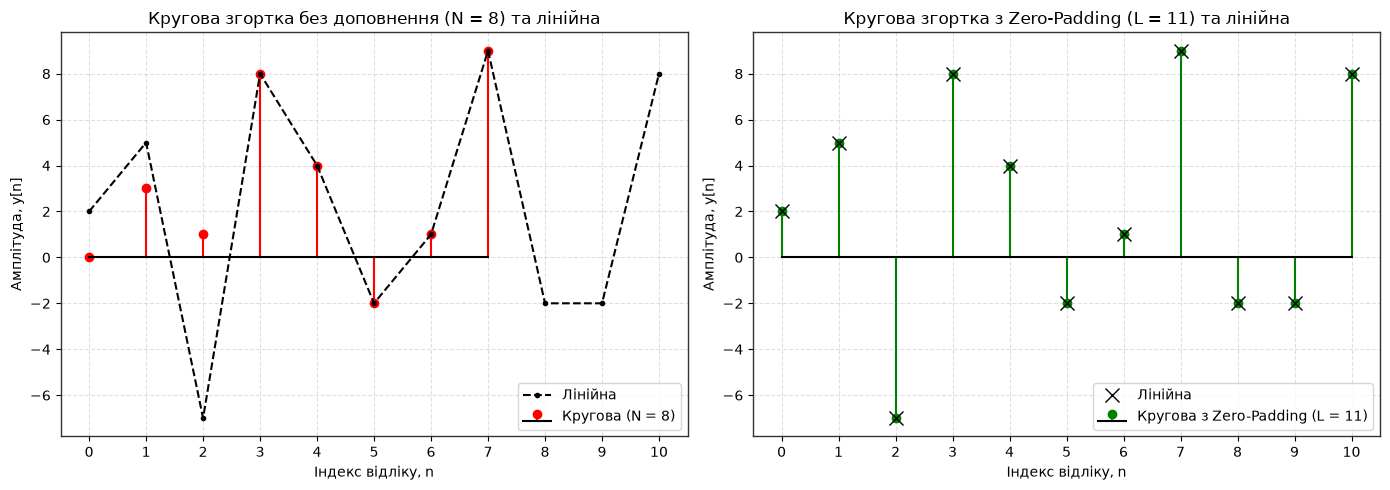


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
x_circ_test = x_bench
h_circ_test = h_bench

y_lin = manual_linear_convolution(x_circ_test, h_circ_test)
y_circ = manual_circular_convolution(x_circ_test, h_circ_test)      # N_c = max(N_x, N_h)

N_c = max(len(x_circ_test), len(h_circ_test))
L_pad = len(x_circ_test) + len(h_circ_test) - 1                     # мінімальна довжина без накладання

x_padded = np.pad(x_circ_test, (0, L_pad - len(x_circ_test)))
h_padded = np.pad(h_circ_test, (0, L_pad - len(h_circ_test)))
y_circ_padded = manual_circular_convolution(x_padded, h_padded)

# перевірка через ДПФ: циклічна згортка = ОДПФ(ДПФ(x) * ДПФ(h))
y_fft = np.real(np.fft.ifft(np.fft.fft(x_padded) * np.fft.fft(h_padded)))

print("\n--- КРУГОВА ТА ЛІНІЙНА ЗГОРТКА ---")
print(f"Лінійна згортка (довжина {len(y_lin)}):      {y_lin.astype(int).tolist()}")
print(f"Кругова, N = {N_c} без доповнення:          {y_circ.astype(int).tolist()}")
print(f"Кругова, L = {L_pad} з Zero-Padding:        {y_circ_padded.astype(int).tolist()}")
print(f"Відхилення кругової (L = {L_pad}) від лінійної: {np.max(np.abs(y_circ_padded - y_lin)):.2e}, "
      f"від ДПФ-розрахунку: {np.max(np.abs(y_circ_padded - y_fft)):.2e}")

# накладання при N = 8: y_c[n] = y[n] + y[n + N] для n = 0 .. N_h - 2
tail = len(y_lin) - N_c
print(f"Накладання хвоста лінійної згортки на перші {tail} відліки:")
for n in range(tail):
    print(f"  y_c[{n}] = y[{n}] + y[{n + N_c}] = {fmt(y_lin[n])} + {fmt(y_lin[n + N_c])} = {y_circ[n]:g}")

# як змінюється результат при різній довжині доповнення
print(f"\n{'L':>3} {'співпадає з лінійною':>22} {'спотворених відліків':>22}")
for L_try in range(N_c, L_pad + 2):
    x_try = np.pad(x_circ_test, (0, L_try - len(x_circ_test)))
    h_try = np.pad(h_circ_test, (0, L_try - len(h_circ_test)))
    y_try = manual_circular_convolution(x_try, h_try)
    y_ref = np.pad(y_lin, (0, max(0, L_try - len(y_lin))))[:L_try]
    n_bad = int(np.sum(np.abs(y_try - y_ref) > 1e-9))
    print(f"{L_try:3d} {'так' if n_bad == 0 else 'ні':>22} {n_bad:22d}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stem(np.arange(len(y_circ)), y_circ, linefmt='r-', markerfmt='ro', basefmt='k-',
             label=f'Кругова (N = {N_c})')
axes[0].plot(np.arange(len(y_lin)), y_lin, 'k--', marker='.', label='Лінійна')
axes[0].set_title(f"Кругова згортка без доповнення (N = {N_c}) та лінійна")
axes[0].set_xlabel("Індекс відліку, n")
axes[0].set_ylabel("Амплітуда, y[n]")
axes[0].set_xticks(np.arange(len(y_lin)))
axes[0].grid(True)
axes[0].legend(loc='lower right')

axes[1].stem(np.arange(len(y_circ_padded)), y_circ_padded, linefmt='g-', markerfmt='go', basefmt='k-',
             label=f'Кругова з Zero-Padding (L = {L_pad})')
axes[1].plot(np.arange(len(y_lin)), y_lin, 'kx', markersize=10, label='Лінійна')
axes[1].set_title(f"Кругова згортка з Zero-Padding (L = {L_pad}) та лінійна")
axes[1].set_xlabel("Індекс відліку, n")
axes[1].set_ylabel("Амплітуда, y[n]")
axes[1].set_xticks(np.arange(len(y_lin)))
axes[1].grid(True)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig("figures/circular_vs_linear_conv.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати для кругової та лінійної згортки** ($N_x = 8$, $N_h = 4$):

| Згортка | Результат |
|---|---|
| лінійна, довжина 11 | [2, 5, −7, 8, 4, −2, 1, 9, −2, −2, 8] |
| кругова, $N = 8$ (без доповнення) | [0, 3, 1, 8, 4, −2, 1, 9] |
| кругова, $L = 11$ (Zero-Padding) | [2, 5, −7, 8, 4, −2, 1, 9, −2, −2, 8] |

Без доповнення відліки $n = 3 \dots 7$ збігаються з лінійною згорткою, а $n = 0, 1, 2$ спотворені накладанням «хвоста» $y[8], y[9], y[10]$: $y_c[0] = 2 + (-2) = 0$, $y_c[1] = 5 + (-2) = 3$, $y_c[2] = -7 + 8 = 1$. Після доповнення нулями до $L = 11$ результат збігається з лінійною згорткою і з розрахунком через ДПФ (відхилення порядок $10^{-15}$). Перебір довжини показує: при $L = 8, 9, 10$ спотворено відповідно 3, 2 та 1 відлік, починаючи з $L = 11 = N_x + N_h - 1$ спотворень немає.

## 5. Висновки

1. Власна функція лінійної згортки за означенням дає результат довжиною $N_x + N_h - 1 = 11$, який збігається з `np.convolve` та `scipy.signal.convolve`. Перші чотири такти ($2, 5, -7, 8$) збігаються з аналітичним розрахунком. Прямий алгоритм потребує $N_x N_h$ множень, тобто має складність $O(N_x N_h)$ ($O(N^2)$ при однакових довжинах): за вимірами час зростає приблизно в 4 рази при подвоєнні довжини. Для довгих сигналів швидші алгоритми на основі ШПФ зі складністю $O(N \log N)$.

2. Ковзне середнє довжини $M = 5$ є фільтром нижніх частот: прямокутний імпульс довжиною 6 перетворюється на трапецію тривалістю $L + M - 1 = 10$ відліків із лінійними фронтами завширшки $M - 1 = 4$, а експоненційний сигнал згладжується, і його початковий стрибок розтягується на $M - 1$ відліки. АЧХ $|H_{ma}(0)| = 1$ та $|H_{ma}(\pi)| = 1/M = 0.2$ підтверджує послаблення високих частот. Ціною згладжування є розмивання країв сигналу.

3. Диференціатор $y[n] = x[n] - x[n-1]$ виділяє швидкі зміни сигналу: на прямокутному імпульсі він дає лише два відліки, $+1$ на передньому фронті ($n = 0$) і $-1$ на задньому ($n = 6$), а на сталих ділянках вихід нульовий. Для експоненти вихід дорівнює $A\alpha^{n-1}(\alpha - 1)$ (від'ємний, спадний), крім стрибка $+A = 1.5$ на початку. Оскільки $|H_{diff}(0)| = 0$ і $|H_{diff}(\pi)| = 2$, постійна складова пригнічується, а високі частоти (зокрема шум) підсилюються.

4. Система другого порядку з коефіцієнтами варіанта 2 має полюси $z = 0.3$ і $z = 0.4$, тому вона стійка. Імпульсна характеристика нескінченна через зворотний зв'язок, але швидко спадає ($|h[n]| < 10^{-3}$ при $n \ge 10$). Перехідна характеристика прямує до $H(1) = 10/7 \approx 1.4286$. Рекурентна реалізація збігається з `scipy.signal.lfilter` з точністю до $10^{-16}$.

5. Кругова згортка довжини $N = 8$ без доповнення відрізняється від лінійної: хвіст лінійної згортки ($y[8], y[9], y[10]$) накладається на перші три відліки (часове аліасування), через що $y_c[0..2] = 0, 3, 1$ замість $2, 5, -7$. Кругова згортка збігається з лінійною за умови доповнення нулями до $L \ge N_x + N_h - 1 = 11$ (експеримент: при $L = 8, 9, 10$ спотворені 3, 2, 1 відліки, при $L = 11$ та $L = 12$ спотворень немає).

## Відповідь на контрольні питання

**1. Сформулюйте математичні критерії лінійності та стаціонарності для дискретних систем обробки сигналів.**

Нехай $T\{\cdot\}$ — оператор дискретної системи, що перетворює вхідний сигнал $x[n]$ у вихідний $y[n] = T\{x[n]\}$.

* **Критерій лінійності (принцип суперпозиції):** Система є лінійною тоді й лише тоді, коли для будь-яких двох вхідних послідовностей $x_1[n], x_2[n]$ та довільних констант $a, b$ виконується умова адитивності та однорідності:

$$T\{a \cdot x_1[n] + b \cdot x_2[n]\} = a \cdot T\{x_1[n]\} + b \cdot T\{x_2[n]\} = a \cdot y_1[n] + b \cdot y_2[n]$$


* **Критерій стаціонарності (інваріантності в часі):** Система є стаціонарною, якщо довільний часовий зсув вхідного сигналу на цілу кількість відліків $n_0$ призводить до такого самого часового зсуву вихідного сигналу без зміни його форми:

$$\text{Якщо } y[n] = T\{x[n]\}, \text{ то } T\{x[n - n_0]\} = y[n - n_0] \quad \forall n_0 \in \mathbb{Z}$$



---

**2. Чому імпульсна характеристика $h[n]$ є вичерпним описом лінійної стаціонарної дискретної системи у часовій області?**

* Будь-який довільний дискретний сигнал $x[n]$ можна розкласти у вигляді зваженої суми зсунутих у часі одиничних імпульсів (дельта-функцій Кронекера $\delta[n]$):

$$x[n] = \sum_{k=-\infty}^{\infty} x[k] \cdot \delta[n - k]$$


* За означенням імпульсна характеристика $h[n] = T\{\delta[n]\}$ — це відгук системи на одиничний імпульс $\delta[n]$.
* Завдяки властивості **стаціонарності** відгук системи на зсунутий одиничний імпульс $\delta[n - k]$ дорівнює зсунутій імпульсній характеристиці $h[n - k]$.
* Завдяки властивості **лінійності** реакція системи $y[n]$ на весь вхідний сигнал $x[n]$ дорівнює сумі реакцій на кожен окремий зважений імпульс, тобто дискретній лінійній згортці:

$$y[n] = T\left\{\sum_{k=-\infty}^{\infty} x[k] \cdot \delta[n - k]\right\} = \sum_{k=-\infty}^{\infty} x[k] \cdot h[n - k] = (x * h)[n]$$


* Отже, знаючи лише $h[n]$, можна однозначно обчислити реакцію лінійної стаціонарної системи на будь-який можливий вхідний сигнал без необхідності знати її внутрішню будову.

---

**3. Яким чином визначається результуюча тривалість лінійної згортки двох скінченних послідовностей довжиною $N_x$ та $N_h$?**

Якщо перша послідовність $x[n]$ має довжину $N_x$ (відліки з індексами $0 \le n \le N_x - 1$), а друга $h[n]$ має довжину $N_h$ (індекси $0 \le n \le N_h - 1$), то ненульові відліки їхньої лінійної згортки $y[n] = \sum_{k=0}^{N_x - 1} x[k] \cdot h[n - k]$ лежать у межах від $n_{\min} = 0$ до $n_{\max} = (N_x - 1) + (N_h - 1) = N_x + N_h - 2$.

Відповідно, результуюча тривалість (загальна кількість відліків) лінійної згортки дорівнює:


$$N_y = N_x + N_h - 1$$

---

**4. У чому полягає відмінність між фізичним змістом операцій лінійної та кругової (циклічної) дискретної згортки?**

* **Лінійна згортка:** Описує реальний фізичний процес проходження скінченного або нескінченного сигналу через лінійну стаціонарну систему (фільтр). Поза межами інтервалу задання послідовностей їхні значення вважаються рівними **нулю**, тому перехідні процеси на початку (поступове заповнення пам'яті фільтра) та в кінці (затухання відгуку після завершення вхідного сигналу) відтворюються фізично коректно.
* **Кругова (циклічна) згортка:** Описує взаємодію **періодичних** сигналів з однаковим періодом $N$ (або послідовностей, розміщених на замкненому колі з $N$ точок). При зсуві відліки, які виходять за межі інтервалу $[0, N-1]$, циклічно переносяться на його протилежний край (індексація за модулем $N$: $h[(n - k) \bmod N]$). У частотній області поточковому множенню ДПФ довжини $N$ відповідає саме кругова згортка, через що без попереднього доповнення нулями «хвіст» відгуку накладається на початок сигналу (виникає ефект часового аліасингу).

---

**5. Яку мінімальну кількість нульових відліків (Zero-Padding) необхідно додати до вхідних послідовностей, щоб результат кругової згортки збігався з лінійною?**

Щоб кругова згортка розмірності $N$ повністю збігалася з лінійною згорткою без накладання відліків, її довжина $N$ повинна бути не меншою за тривалість лінійної згортки:


$$N \ge N_x + N_h - 1$$

Відповідно, мінімальна кількість нулів, яку необхідно дописати в кінець кожної послідовності, становить:

* до послідовності $x[n]$ довжини $N_x$ потрібно додати мінімум **$N_h - 1$** нульових відліків;
* до послідовності $h[n]$ довжини $N_h$ потрібно додати мінімум **$N_x - 1$** нульових відліків.

*(Примітка: при обчисленні через стандартний алгоритм ШПФ за основою 2 обидві послідовності доповнюють нулями до найближчого цілого степеня двійки $N_{\text{FFT}} = 2^\nu \ge N_x + N_h - 1$.)*

---

**6. Як впливає система ковзного середнього (Moving Average) на високочастотні та низькочастотні складові вхідного сигналу?**

Система ковзного середнього з вікном довжини $M$ обчислює середнє арифметичне $M$ останніх відліків: $y[n] = \frac{1}{M} \sum_{k=0}^{M-1} x[n - k]$ (її імпульсна характеристика має прямокутну форму $h[n] = \frac{1}{M}$ при $0 \le n \le M-1$). За своєю суттю це **фільтр нижніх частот (ФНЧ)** зі скінченною імпульсною характеристикою (СІХ):

* **Низькочастотні складові (та постійна складова $\omega = 0$):** Пропускаються практично без ослаблення (на нульовій частоті коефіцієнт підсилення $\vert{}H(e^{j0})\vert{} = 1$), оскільки повільні зміни сигналу на інтервалі усереднення $M$ мало відхиляються від середнього значення.
* **Високочастотні складові (швидкі осциляції, імпульсні завади, білий шум):** Сильно **придушуються (згладжуються)**, оскільки швидкі коливання протилежних знаків у межах вікна $M$ взаємно компенсуються під час підсумовування. АЧХ фільтра описується функцією $\left\vert{}\frac{\sin(\omega M / 2)}{M \sin(\omega / 2)}\right\vert{}$, завдяки чому гармоніки з частотами, кратними $f_s / M$, подавлюються повністю (нулі АЧХ).

---

**7. Чому наявність ненульових коефіцієнтів зворотного зв'язку $a_k$ ($k \ge 1$) у різницевому рівнянні призводить до виникнення нескінченної імпульсної характеристики (НІХ)?**

Загальне лінійне різницеве рівняння рекурсивного фільтра має вигляд:


$$y[n] = \sum_{m=0}^{M} b_m x[n - m] - \sum_{k=1}^{K} a_k y[n - k]$$

Ненульові коефіцієнти $a_k$ ($k \ge 1$) задають **зворотний зв'язок (рекурсію)**: поточний вихідний відлік $y[n]$ обчислюється не тільки на основі вхідних відліків $x[n - m]$, а й з використанням попередніх вихідних значень $y[n - k]$.

Якщо подати на вхід одиничний імпульс $x[n] = \delta[n]$, який дорівнює нулю для всіх $n > 0$, вихідний сигнал $y[n]$ після початкового збудження при $n = 0$ продовжує рекурсивно формуватися за рахунок власних попередніх ненульових значень $y[n-1], y[n-2], \dots$ на кожному наступному такті. Через циркуляцію енергії в петлі зворотного зв'язку відгук системи теоретично триває нескінченно довго ($h[n] \ne 0$ при $n \to \infty$, зазвичай експоненційно затухаючи для стійкої системи), що й визначає нескінченну імпульсну характеристику (НІХ).